## Homework 3

> [!NOTE]
> This homework uses the pinned 2026 lead-scoring release in the course
> repository. The plan and report are available in `cohorts/2026/data/`.


### Dataset

In this homework, we will use the 2026 lead-scoring dataset. Download it from [here](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv).



Or you can do it with `wget`:

```bash
wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
```


In this dataset our desired target for classification task will be `converted` variable - has the client signed up to the platform or not.

### Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 



In [35]:
from pathlib import Path
import sys

repo_root = Path.cwd()
if not (repo_root / "hlib").is_dir():
    repo_root = repo_root.parent

sys.path.insert(0, str(repo_root))

from hlib.data import IOData
from hlib.preprocessing import fill_nan_values_of_model_data

In [36]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split

In [37]:
target = 'converted'
DF = pd.read_csv("/workspaces/ZoomML_Homeworks/homework_3/course_lead_scoring_2026.csv")

df = DF.copy()


In [38]:
num_cols = df.select_dtypes(include=['number']).columns
cat_cols = df.select_dtypes(include=["str", "object"]).columns


# df[cat_cols] = df[cat_cols].astype('category')

df[num_cols] = df[num_cols].fillna(0.0)
df[cat_cols] = df[cat_cols].fillna('NA')

df.isna().any()

lead_source                 False
industry                    False
employment_status           False
location                    False
annual_income               False
number_of_courses_viewed    False
interaction_count           False
lead_score                  False
converted                   False
dtype: bool

### Question 1

What is the most frequent observation (mode) for the column `industry`?

- `NA`
- `technology`
- `healthcare`
- `retail`



In [39]:
df.industry.value_counts().idxmax()

'technology'

### Question 2

Create the [correlation matrix](https://www.google.com/search?q=correlation+matrix) for the numerical features of your dataset.
In a correlation matrix, you compute the correlation coefficient between every pair of features.

What are the two features that have the biggest correlation?

- `interaction_count` and `lead_score`
- `number_of_courses_viewed` and `lead_score`
- `number_of_courses_viewed` and `interaction_count`
- `annual_income` and `interaction_count`

Only consider the pairs above when answering this question.



<Axes: >

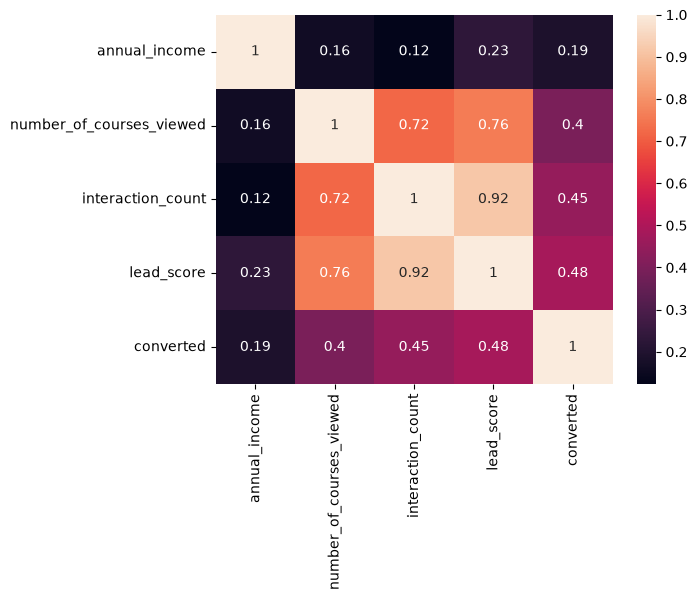

In [40]:
sns.heatmap(df[num_cols].corr(), 
annot=True
    )

In [41]:
corr = df[num_cols].corr()
corr = corr.mask(np.eye(len(corr), dtype=bool))

coppia = corr.stack().idxmax()
valore = corr.stack().max()

print(coppia, valore)

('interaction_count', 'lead_score') 0.9157457980418697


### Split the data

- Split the data with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)
```

- Make sure that the target value `converted` is not in your dataframe.


In [42]:
from hlib.data import split_feature_target_columns
from hlib.data import ModelData


In [43]:
feature_cols = df.columns.to_list()
feature_cols.remove(target)

target_cols = [target]

In [44]:

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [45]:
D = ModelData(
    train=split_feature_target_columns(df_train, target_cols),
    val=split_feature_target_columns(df_val, target_cols),
    test=split_feature_target_columns(df_test, target_cols),
)

### Question 3

- Calculate the mutual information score between `converted` and other categorical variables in the dataset. Use the training set only.
- Round the scores to 2 decimals using `round(score, 2)`.

Which of these variables has the biggest mutual information score?

- `industry`
- `location`
- `lead_source`
- `employment_status`



In [46]:
from sklearn.metrics import mutual_info_score


for col in cat_cols:
    mis = mutual_info_score(D.train.targets[target], D.train.features[col])
    print(f"MIS({target},{col}): {mis:.2f}")

MIS(converted,lead_source): 0.03
MIS(converted,industry): 0.00
MIS(converted,employment_status): 0.02
MIS(converted,location): 0.00


In [47]:
D.train.y.ravel()

array([1, 0, 1, ..., 1, 0, 0], shape=(3000,))

### Question 4

- Now let's train a logistic regression.
- Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.
- Fit the model on the training dataset.
  - To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:
  - `model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)`
- Calculate the accuracy on the validation dataset and round it to 2 decimal digits.

What accuracy did you get?

- 0.55
- 0.65
- 0.75
- 0.85



In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction import DictVectorizer

In [49]:
dv = DictVectorizer(sparse=False)

In [50]:
feature_cols = [
    c for c in list(num_cols) + list(cat_cols)
    if c != "converted"
]

train_dict = D.train.features[feature_cols].to_dict(orient="records")
D.train.X = dv.fit_transform(train_dict)


In [51]:
val_dict = D.val.features[feature_cols].to_dict(orient="records")
test_dict = D.test.features[feature_cols].to_dict(orient="records")

D.val.X = dv.transform(val_dict)
D.test.X = dv.transform(test_dict)

In [52]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

model.fit(D.train.X,D.train.y.ravel())

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [53]:
y_pred = (model.predict_proba(D.val.X)[:,1]>=0.5).astype(int)

ref_accuracy = accuracy_score(D.val.y, y_pred)
round(ref_accuracy,2)

0.65

### Question 5

- Let's find the least useful feature using the _feature elimination_ technique.
- Train a model using the same features and parameters as in Q4 (without rounding).
- Now exclude each feature from this set and train a model without it. Record the accuracy for each model.
- For each feature, calculate the difference between the original accuracy and the accuracy without the feature.

Which of following feature has the smallest difference?

- `'lead_source'`
- `'number_of_courses_viewed'`
- `'interaction_count'`

> **Note**: The difference doesn't have to be positive.



In [54]:
features_to_remove = ['lead_source','number_of_courses_viewed','interaction_count']
accuracies = {}

target_cols = ['converted']
for f in features_to_remove:
    # dfs = df.copy()
    feature_cols = [
    c for c in df.columns
    if (c != "converted") and (c!=f)
    ]

    
#     dfs = dfs[feature_cols+target_cols]
#     df_full_train, df_test = train_test_split(dfs, test_size=0.2, random_state=42)
#     df_train, df_val = train_test_split(
#     df_full_train, test_size=0.25, random_state=42
# )

#     D = ModelData(
#     train=split_feature_target_columns(df_train, target_cols),
#     val=split_feature_target_columns(df_val, target_cols),
#     test=split_feature_target_columns(df_test, target_cols),
# )
    dv = DictVectorizer(sparse=False)
    train_dict = D.train.features[feature_cols].to_dict(orient="records")
    D.train.X = dv.fit_transform(train_dict)

    val_dict = D.val.features[feature_cols].to_dict(orient="records")
    D.val.X = dv.transform(val_dict)
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

    model.fit(D.train.X,D.train.y.ravel())
    y_pred = (model.predict_proba(D.val.X)[:,1]>=0.5).astype(int)

    current_accuracy = accuracy_score(D.val.y.ravel(), y_pred)
    d =ref_accuracy-current_accuracy
    print(f"Feature removed: {f}")
    print(f"Delta Accuracy: {d}")
    print("\n")

    accuracies[f]=d


min(accuracies.items(), key = lambda x: x[1])

Feature removed: lead_source
Delta Accuracy: 0.0030000000000000027


Feature removed: number_of_courses_viewed
Delta Accuracy: 0.0020000000000000018


Feature removed: interaction_count
Delta Accuracy: 0.04400000000000004




('number_of_courses_viewed', 0.0020000000000000018)

### Question 6

- Now let's train a regularized logistic regression.
- Let's try the following values of the parameter `C`: `[0.000001, 0.00001, 0.0001, 0.001]`.
- Train models using all the features as in Q4.
- Calculate the accuracy on the validation dataset and round it to 3 decimal digits.

Which of these `C` leads to the best accuracy on the validation set?

- 0.000001
- 0.00001
- 0.0001
- 0.001

> **Note**: If there are multiple options, select the smallest `C`.



In [55]:
accuracies = {}
Cs = [0.000001,0.00001,0.0001,0.001]

feature_cols = df.columns.to_list()
feature_cols.remove(target)

results = []
for c in Cs:
    
    dv = DictVectorizer(sparse=False)
    train_dict = D.train.features[feature_cols].to_dict(orient="records")
    D.train.X = dv.fit_transform(train_dict)

    val_dict = D.val.features[feature_cols].to_dict(orient="records")
    D.val.X = dv.transform(val_dict)
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)

    model.fit(D.train.X,D.train.y.ravel())
    y_pred = (model.predict_proba(D.val.X)[:,1]>=0.5).astype(int)

    # current_accuracy = 
    # d = ref_accuracy-current_accuracy
    # accuracies[c]=current_accuracy

    results.append({
        "C":c,
        "accuracy":accuracy_score(D.val.y.ravel(), y_pred)
    })

pd.DataFrame(results).set_index("C").idxmax()

accuracy    0.001
dtype: float64

## Submit the results

- Submit your results here: https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw03
- The numerical options are calculated from the pinned 2026 release. Use the value that matches your calculation; do not choose a merely close value.